# 互信息

互信息衡量知道$X_{t-k}$后，对$X_{t+1}$不确定性的平均减少量
$$
I(X_{t-k},X_{t+1})=\int\int p(x_{t-k},x_{t+1})\log\frac{p(x_{t-k},x_{t+1})}{p(x_{t-k})p(x_{t+1})}dx_{t-k}dx_{t+1}
$$

可以用直方图法、核密度估计或 kNN 方法计算。

对不同滞后$k=1,2,\cdots,K$，计算$I(X_{t-k},X_{t+1})$，绘制互信息-滞后曲线，通常曲线先快速下降，然后进入平台期。窗口长度取到曲线上“显著信息不再增加”的位置即可。
## 计算方法

### 数据与预处理

- 数据：`data/{btc,eth,bnb,sol,trx,xlm,paxg}_usdt_1h.csv` 七个资产的小时线，均取 2022-01-01 00:00 ~ 2025-12-31 23:00 的收盘价（各 35064 根，无缺失、无重复）。
- 价格序列非平稳（近似随机游走），直接对价格计算互信息会被"价格水平"主导；研究对象取**对数收益率** $r_t=\ln(P_t/P_{t-1})$（近似平稳）。
- 下方用函数 `load_log_returns` / `mi_curve` / `summarize` / `plot_mi_curve` 复用同一套流程，对七个资产循环计算与绘图。

### 估计量：kNN（KSG）方法

对每个滞后 $k=1,\dots,48$ 计算

$$I(r_{t-k};\,r_{t+1})=\iint p(x,y)\log\frac{p(x,y)}{p(x)\,p(y)}\,dx\,dy$$

即"滞后 $k$ 小时的收益率"与"下一小时收益率"之间的互信息（由平稳性，等价于相隔 $k+1$ 小时的观测对之间的互信息）。

直方图法对箱宽敏感、核密度估计大样本下计算量大，这里采用 **k 近邻（KSG, Kraskov–Stögbauer–Grassberger, 2004）估计量**（`sklearn.feature_selection.mutual_info_regression`，`n_neighbors=3`，`random_state=42`），无需分箱：

1. 对每一对观测 $(x_i,y_i)$，在联合空间 $(x,y)$ 中找它的第 $k$ 近邻（本文取 $k=3$），记该近邻距离为 $\varepsilon_i$；
2. 统计 $x$ 轴上落入半径 $\varepsilon_i$ 内的点数 $n_x(i)$、$y$ 轴上落入 $\varepsilon_i$ 内的点数 $n_y(i)$；
3. 估计量
$$\hat{I}=\psi(k)+\psi(N)-\frac{1}{N}\sum_{i=1}^{N}\left[\psi(n_x(i)+1)+\psi(n_y(i)+1)\right]$$
其中 $\psi$ 为 digamma 函数，$N$ 为有效样本数。

### 零依赖基准与显著滞后期

kNN 估计量在有限样本下存在正的估计偏差（噪声底）。对每个滞后将 $r_{t+1}$ **随机置换**（破坏时序依赖、保持边际分布）5 次同法估计，取均值 $\pm 2\sigma$ 作为零依赖基准带。

**互信息高于基准带的滞后视为显著**；首个落入基准带的滞后即"显著信息不再增加"的位置，可作为窗口长度。若 48 小时内始终高于基准带，则依赖呈长尾形态，需延伸滞后观察。


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib import font_manager
from IPython.display import display, Markdown
from sklearn.feature_selection import mutual_info_regression

# ---- 中文字体（优先 Noto Sans CJK SC，避免中文标签乱码） ----
_cjk = [f.name for f in font_manager.fontManager.ttflist
        if f.name in ("Noto Sans CJK SC", "Noto Sans SC", "Source Han Sans SC",
                      "SimHei", "Microsoft YaHei", "PingFang SC", "WenQuanYi Zen Hei")]
if not _cjk:
    _cjk = [f.name for f in font_manager.fontManager.ttflist
            if ("CJK" in f.name or "Han" in f.name)]
if _cjk:
    plt.rcParams["font.family"] = _cjk[0]
    plt.rcParams["axes.unicode_minus"] = False
    print("图表字体:", _cjk[0])
else:
    print("警告：未找到中文字体")

图表字体: Noto Sans CJK SC


In [2]:
START, END = "2022-01-01", "2025-12-31 23:00"
ASSETS = ["BTC", "ETH", "BNB", "SOL", "TRX", "XLM", "PAXG"]
K_MAX = 48

In [3]:
def load_log_returns(asset, start=START, end=END):
    """读取 data/{asset}_usdt_1h.csv 的 [start, end] 收盘价，返回 (收盘价 Series, 对数收益率 Series)。"""
    cand = [Path(f"data/{asset.lower()}_usdt_1h.csv"),
            Path(f"../data/{asset.lower()}_usdt_1h.csv")]
    csv = next((c for c in cand if c.exists()), None)
    if csv is None:
        raise FileNotFoundError(f"未找到 data/{asset.lower()}_usdt_1h.csv")
    df = pd.read_csv(csv, parse_dates=["timestamp"]).set_index("timestamp")
    p = df.loc[start:end, "close"]
    r = np.log(p / p.shift(1)).dropna()
    return p, r


def ks_g_mi(x, y, n_neighbors=3, random_state=42):
    """KSG kNN 互信息估计量（sklearn 实现）。"""
    return mutual_info_regression(x.reshape(-1, 1), y,
                                  n_neighbors=n_neighbors,
                                  random_state=random_state)[0]


def mi_curve(r, k_max=48, n_shuffle=5, seed=42, n_neighbors=3):
    """计算 I(r_{t-k}; r_{t+1})（k=1..k_max）及零依赖置换基准，返回 dict。"""
    lags = np.arange(1, k_max + 1)
    rng = np.random.default_rng(seed)
    mi, null_mean, null_std = [], [], []
    for k in lags:
        x = r.shift(k).to_numpy()      # X_{t-k}：滞后 k 小时的收益率
        y = r.shift(-1).to_numpy()     # X_{t+1}：下一小时收益率
        m = ~(np.isnan(x) | np.isnan(y))
        x, y = x[m], y[m]
        mi.append(ks_g_mi(x, y, n_neighbors))
        nulls = [ks_g_mi(x, rng.permutation(y), n_neighbors)
                 for _ in range(n_shuffle)]
        null_mean.append(np.mean(nulls))
        null_std.append(np.std(nulls))
    return {"lags": lags, "mi": np.asarray(mi),
            "null_mean": np.asarray(null_mean), "null_std": np.asarray(null_std)}


def summarize(asset, p, r, res):
    """汇总单个资产的关键统计（峰值、衰减、显著滞后期、颗粒度诊断）。"""
    mi, lags = res["mi"], res["lags"]
    nm, ns = res["null_mean"], res["null_std"]
    band = nm + 2 * ns
    sig = mi > band
    max_mi = float(mi.max())
    k_peak = int(lags[int(np.argmax(mi))])
    mi_k10 = float(mi[9]) if len(mi) >= 10 else float(mi[-1])
    idx = np.where((~sig) & (lags >= 6))[0]
    k_first_null = int(lags[idx[0]]) if len(idx) else None
    if k_first_null is None:
        sig_desc = "k=1..48 全部显著（48h 内无平台期）"
    else:
        tail = [int(k) for k in lags[(lags > k_first_null) & sig]]
        sig_desc = f"k=1..{k_first_null - 1} 显著；k={k_first_null} 起进入基准带"
        if tail:
            sig_desc += f"（其后零星显著：{tail}）"
    rr = r.to_numpy()
    return {
        "asset": asset, "max_mi": max_mi, "k_peak": k_peak,
        "mi_k10": mi_k10, "frac_k10": mi_k10 / max_mi,
        "k_first_null": k_first_null, "sig_desc": sig_desc,
        "zr": float(np.mean(rr == 0)), "ur": float(len(np.unique(rr)) / len(rr)),
        "rho_abs": float(np.corrcoef(np.abs(rr[:-1]), np.abs(rr[1:]))[0, 1]),
        "acf1": float(np.corrcoef(rr[:-1], rr[1:])[0, 1]),
        "n_bars": int(len(p)), "n_returns": int(len(r)),
    }


def compute_all(assets, k_max=48):
    """对多个资产计算互信息曲线与汇总统计，返回 {asset: {"res":.., "summary":..}}。"""
    out = {}
    for asset in assets:
        p, r = load_log_returns(asset)
        res = mi_curve(r, k_max=k_max)
        out[asset] = {"res": res, "summary": summarize(asset, p, r, res)}
    return out


def plot_mi_curve(asset, res):
    """绘制单个资产的互信息-滞后曲线（含零依赖基准带），返回 figure。"""
    lags, mi = res["lags"], res["mi"]
    nm, ns = res["null_mean"], res["null_std"]
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(lags, mi, "o-", ms=4, lw=1.5, label=r"$I(r_{t-k}; r_{t+1})$")
    ax.fill_between(lags, nm - 2 * ns, nm + 2 * ns, color="gray", alpha=0.25,
                    label="零依赖基准（置换 5 次，均值±2σ）")
    ax.plot(lags, nm, "--", color="gray", lw=1.0)
    ax.axhline(0, color="k", lw=0.6)
    ax.set_xlabel("滞后 k（小时）")
    ax.set_ylabel("互信息（nats）")
    ax.set_title(f"{asset} 小时对数收益率 互信息-滞后曲线（2022-01-01 ~ 2025-12-31）")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper right")
    plt.tight_layout()
    return fig


## 七资产互信息-滞后曲线

对 BTC、ETH、BNB、SOL、TRX、XLM、PAXG 七个资产循环计算 $I(r_{t-k};r_{t+1})$（$k=1,\dots,48$），并分别绘制互信息-滞后曲线（灰带为零依赖基准）。

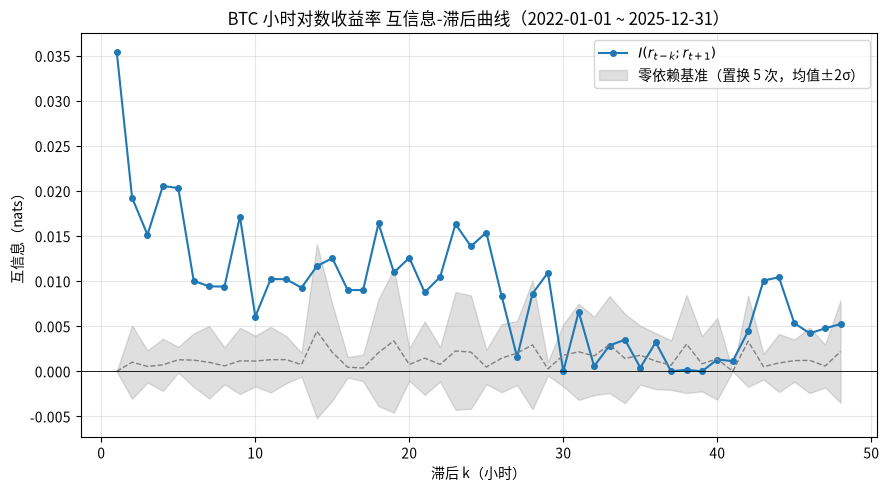

BTC: 峰值 0.0355 nats @ k=1 | k=10 占峰值 17% | 首个进入基准带 k=14 | 显著滞后期 k=1..13 显著；k=14 起进入基准带（其后零星显著：[15, 16, 17, 18, 20, 21, 22, 23, 24, 25, 26, 29, 41, 43, 44, 45, 47]）


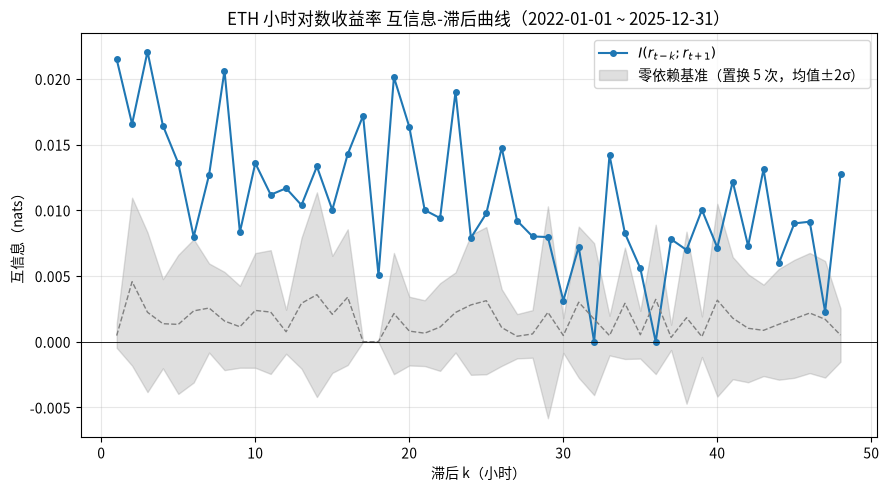

ETH: 峰值 0.0221 nats @ k=3 | k=10 占峰值 62% | 首个进入基准带 k=24 | 显著滞后期 k=1..23 显著；k=24 起进入基准带（其后零星显著：[25, 26, 27, 28, 30, 33, 34, 35, 37, 39, 41, 42, 43, 44, 45, 46, 48]）


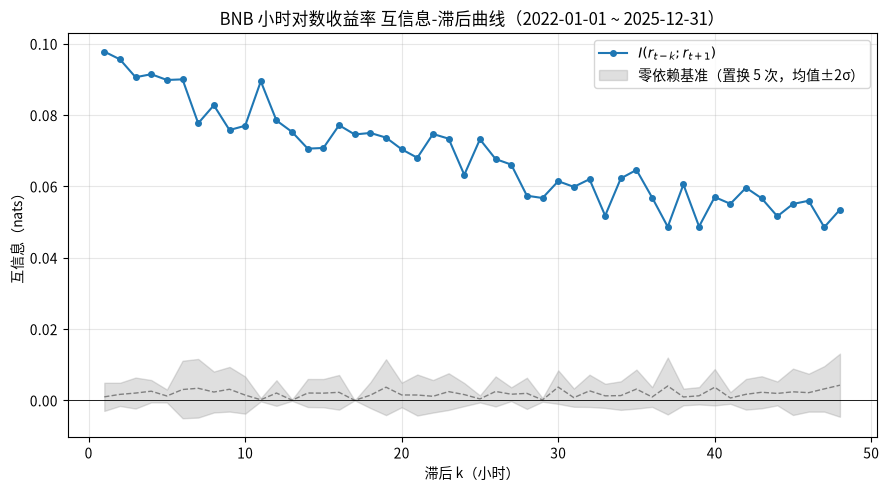

BNB: 峰值 0.0978 nats @ k=1 | k=10 占峰值 79% | 首个进入基准带 k=None | 显著滞后期 k=1..48 全部显著（48h 内无平台期）


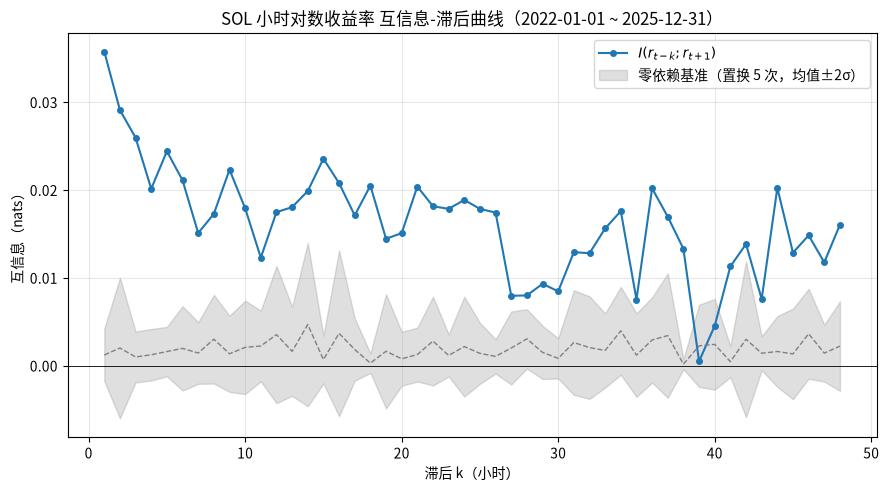

SOL: 峰值 0.0357 nats @ k=1 | k=10 占峰值 50% | 首个进入基准带 k=39 | 显著滞后期 k=1..38 显著；k=39 起进入基准带（其后零星显著：[41, 42, 43, 44, 45, 46, 47, 48]）


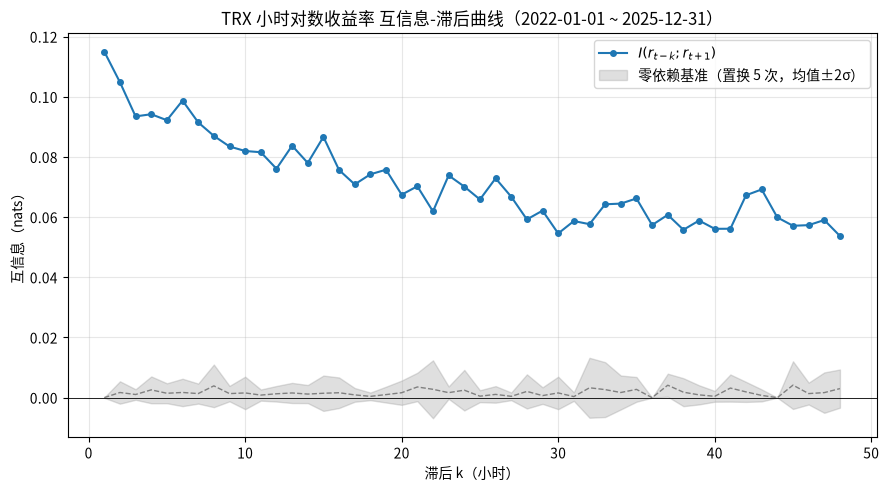

TRX: 峰值 0.1150 nats @ k=1 | k=10 占峰值 71% | 首个进入基准带 k=None | 显著滞后期 k=1..48 全部显著（48h 内无平台期）


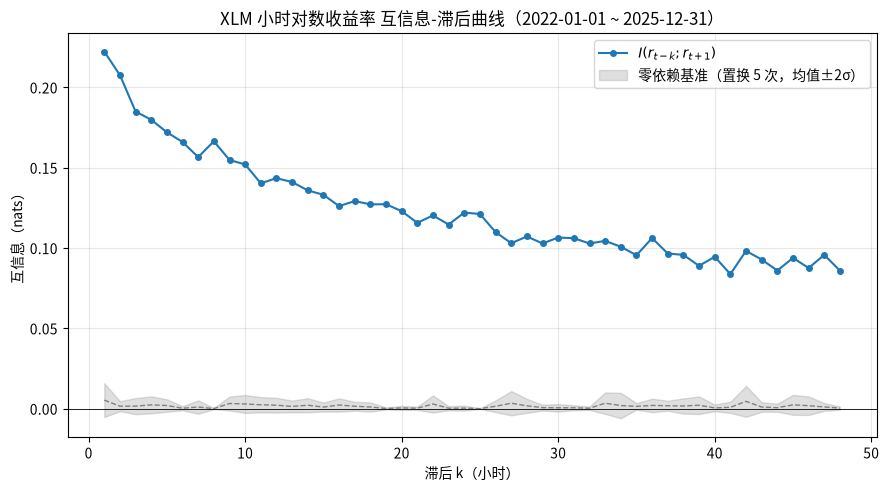

XLM: 峰值 0.2223 nats @ k=1 | k=10 占峰值 68% | 首个进入基准带 k=None | 显著滞后期 k=1..48 全部显著（48h 内无平台期）


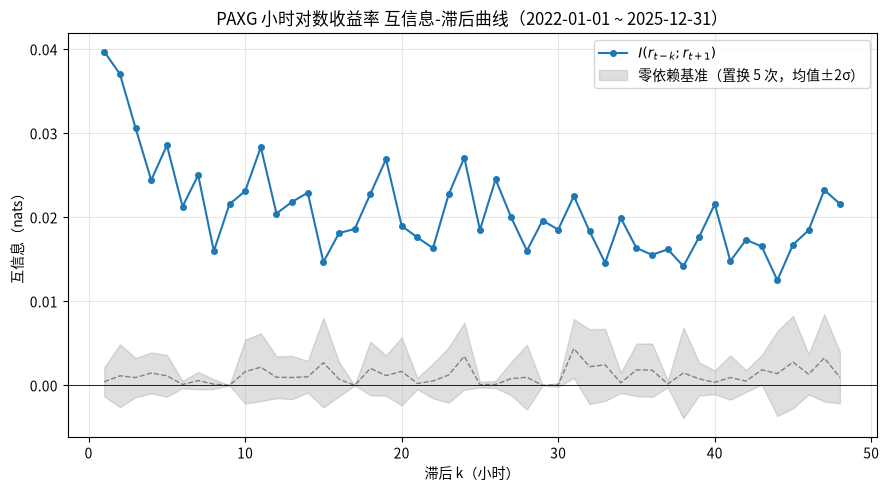

PAXG: 峰值 0.0397 nats @ k=1 | k=10 占峰值 58% | 首个进入基准带 k=None | 显著滞后期 k=1..48 全部显著（48h 内无平台期）


In [4]:
allres = compute_all(ASSETS, k_max=K_MAX)
for asset in ASSETS:
    s = allres[asset]["summary"]
    fig = plot_mi_curve(asset, allres[asset]["res"])
    display(fig)
    plt.close(fig)
    print(f"{asset}: 峰值 {s['max_mi']:.4f} nats @ k={s['k_peak']} | "
          f"k=10 占峰值 {100 * s['frac_k10']:.0f}% | "
          f"首个进入基准带 k={s['k_first_null']} | 显著滞后期 {s['sig_desc']}")

In [5]:
def render_interp(assets, allres):
    """从计算结果生成结果解读（汇总表 + 逐资产显著滞后期）。"""
    lines = ["## 结果解读", ""]
    lines.append(
        "**显著滞后期判定**：滞后 $k$ 的互信息 $I(r_{t-k};r_{t+1})$ 高于零依赖基准带"
        "（$r_{t+1}$ 随机置换 5 次，均值 $+2\\sigma$）即视为显著；"
        "首个落入基准带的滞后即“显著信息不再增加”的位置，可作为窗口长度。")
    lines.append("")
    lines.append("| 资产 | 峰值 MI (nats) | 峰值滞后 | k=10 占峰值 | 首个进入基准带 | 显著滞后期 |")
    lines.append("|---|---|---|---|---|---|")
    for a in assets:
        s = allres[a]["summary"]
        kfn = "—" if s["k_first_null"] is None else str(s["k_first_null"])
        lines.append(
            f"| {a} | {s['max_mi']:.4f} | {s['k_peak']} | "
            f"{100 * s['frac_k10']:.0f}% | {kfn} | {s['sig_desc']} |")
    lines.append("")
    lines.append("**逐资产解读**：")
    lines.append("")
    for a in assets:
        s = allres[a]["summary"]
        if s["k_first_null"] is not None:
            lines.append(
                f"- **{a}**：显著滞后期 $k=1\\sim{s['k_first_null'] - 1}$"
                f"（$k={s['k_first_null']}$ 起进入基准带）；峰值 $\\approx {s['max_mi']:.4f}$ nats"
                f" @ $k={s['k_peak']}$，$k=10$ 已衰减至峰值的 {100 * s['frac_k10']:.0f}%；"
                f"窗口长度取 $k\\le{s['k_first_null'] - 1}$ 小时。")
        elif s["zr"] > 0.3:  # 极端颗粒度（PAXG）
            lines.append(
                f"- **{a}**（极端颗粒度）：$k=1\\sim48$ 全部显著（48h 内无平台期）、慢衰减；"
                f"零收益率占比 {100 * s['zr']:.0f}%、相邻 $|r|$ 相关 {s['rho_abs']:.2f}、"
                f"ACF(1)≈{s['acf1']:.2f}——互信息主要反映平盘/报价跳动/波动率聚集等微观结构与非线性依赖，"
                f"而非可利用的方向性动量，窗口选取需谨慎。")
        else:
            lines.append(
                f"- **{a}**：$k=1\\sim48$ 全部显著（48h 内无平台期）、慢衰减；"
                f"峰值 $\\approx {s['max_mi']:.4f}$ nats @ $k={s['k_peak']}$，"
                f"主要来自波动率聚集（相邻 $|r|$ 相关 {s['rho_abs']:.2f}），"
                f"方向性自相关弱（ACF(1)≈{s['acf1']:.2f}）；窗口需放宽至 $24\\sim48$ 小时甚至更长。")
    lines.append("")
    lines.append(
        "**稳健性说明**：显著滞后期通过与同一边际分布、同一估计量的零依赖基准比较得到，"
        "对估计量绝对水平的敏感性稳健；但 TRX/XLM/BNB 的收益率离散化程度较高、PAXG 尤甚"
        "（多数小时价格不动），这些资产的互信息**绝对水平宜谨慎解读**，"
        "跨资产比较应侧重显著滞后期与衰减形态。")
    return "\n".join(lines) + "\n"


display(Markdown(render_interp(ASSETS, allres)))

## 结果解读

**显著滞后期判定**：滞后 $k$ 的互信息 $I(r_{t-k};r_{t+1})$ 高于零依赖基准带（$r_{t+1}$ 随机置换 5 次，均值 $+2\sigma$）即视为显著；首个落入基准带的滞后即“显著信息不再增加”的位置，可作为窗口长度。

| 资产 | 峰值 MI (nats) | 峰值滞后 | k=10 占峰值 | 首个进入基准带 | 显著滞后期 |
|---|---|---|---|---|---|
| BTC | 0.0355 | 1 | 17% | 14 | k=1..13 显著；k=14 起进入基准带（其后零星显著：[15, 16, 17, 18, 20, 21, 22, 23, 24, 25, 26, 29, 41, 43, 44, 45, 47]） |
| ETH | 0.0221 | 3 | 62% | 24 | k=1..23 显著；k=24 起进入基准带（其后零星显著：[25, 26, 27, 28, 30, 33, 34, 35, 37, 39, 41, 42, 43, 44, 45, 46, 48]） |
| BNB | 0.0978 | 1 | 79% | — | k=1..48 全部显著（48h 内无平台期） |
| SOL | 0.0357 | 1 | 50% | 39 | k=1..38 显著；k=39 起进入基准带（其后零星显著：[41, 42, 43, 44, 45, 46, 47, 48]） |
| TRX | 0.1150 | 1 | 71% | — | k=1..48 全部显著（48h 内无平台期） |
| XLM | 0.2223 | 1 | 68% | — | k=1..48 全部显著（48h 内无平台期） |
| PAXG | 0.0397 | 1 | 58% | — | k=1..48 全部显著（48h 内无平台期） |

**逐资产解读**：

- **BTC**：显著滞后期 $k=1\sim13$（$k=14$ 起进入基准带）；峰值 $\approx 0.0355$ nats @ $k=1$，$k=10$ 已衰减至峰值的 17%；窗口长度取 $k\le13$ 小时。
- **ETH**：显著滞后期 $k=1\sim23$（$k=24$ 起进入基准带）；峰值 $\approx 0.0221$ nats @ $k=3$，$k=10$ 已衰减至峰值的 62%；窗口长度取 $k\le23$ 小时。
- **BNB**：$k=1\sim48$ 全部显著（48h 内无平台期）、慢衰减；峰值 $\approx 0.0978$ nats @ $k=1$，主要来自波动率聚集（相邻 $|r|$ 相关 0.29），方向性自相关弱（ACF(1)≈-0.02）；窗口需放宽至 $24\sim48$ 小时甚至更长。
- **SOL**：显著滞后期 $k=1\sim38$（$k=39$ 起进入基准带）；峰值 $\approx 0.0357$ nats @ $k=1$，$k=10$ 已衰减至峰值的 50%；窗口长度取 $k\le38$ 小时。
- **TRX**：$k=1\sim48$ 全部显著（48h 内无平台期）、慢衰减；峰值 $\approx 0.1150$ nats @ $k=1$，主要来自波动率聚集（相邻 $|r|$ 相关 0.40），方向性自相关弱（ACF(1)≈0.04）；窗口需放宽至 $24\sim48$ 小时甚至更长。
- **XLM**：$k=1\sim48$ 全部显著（48h 内无平台期）、慢衰减；峰值 $\approx 0.2223$ nats @ $k=1$，主要来自波动率聚集（相邻 $|r|$ 相关 0.33），方向性自相关弱（ACF(1)≈-0.05）；窗口需放宽至 $24\sim48$ 小时甚至更长。
- **PAXG**（极端颗粒度）：$k=1\sim48$ 全部显著（48h 内无平台期）、慢衰减；零收益率占比 70%、相邻 $|r|$ 相关 0.45、ACF(1)≈-0.44——互信息主要反映平盘/报价跳动/波动率聚集等微观结构与非线性依赖，而非可利用的方向性动量，窗口选取需谨慎。

**稳健性说明**：显著滞后期通过与同一边际分布、同一估计量的零依赖基准比较得到，对估计量绝对水平的敏感性稳健；但 TRX/XLM/BNB 的收益率离散化程度较高、PAXG 尤甚（多数小时价格不动），这些资产的互信息**绝对水平宜谨慎解读**，跨资产比较应侧重显著滞后期与衰减形态。
